# 02_kNN — TV2: k-Nearest Neighbors | Đề tài 46 – Heart Disease
**Phạm vi:** (1) tìm `k` tối ưu, (2) so sánh Euclidean vs Manhattan, (3) chứng minh tác dụng của `StandardScaler`.  
**Protocol:** `RANDOM_STATE=42`, `StratifiedKFold(5, shuffle=True, random_state=42)`, chọn tham số theo **ROC-AUC**, scaler nằm trong `Pipeline` (fit theo từng fold → không leakage). Test set chỉ dùng 1 lần ở cuối.

## 0. Setup

In [11]:
import os, glob, shutil, zipfile

# 1) Tìm file .zip trong runtime; nếu chưa có thì mở hộp thoại để upload
zips = glob.glob("*.zip")
if not zips:
    from google.colab import files
    zips = [k for k in files.upload() if k.lower().endswith(".zip")]
assert zips, "Chưa upload được file .zip nào"
zip_path = zips[0]

# 2) Giải nén ra thư mục tạm
shutil.rmtree("_unzip", ignore_errors=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall("_unzip")

# 3) Tìm đúng thư mục chứa X_train_raw.csv (dù zip có lồng folder hay không) rồi copy vào data/
hits = glob.glob("_unzip/**/X_train_raw.csv", recursive=True)
assert hits, f"Trong {zip_path} không có X_train_raw.csv -> zip sai hoặc folder data trên Drive đang trống"
src = os.path.dirname(hits[0])
os.makedirs("data", exist_ok=True)
for f in os.listdir(src):
    shutil.copy(os.path.join(src, f), "data")

print(zip_path, "->", sorted(os.listdir("data")))

data-20261030T123700Z-1-001.zip -> ['X_test.npy', 'X_test_raw.csv', 'X_train.npy', 'X_train_raw.csv', 'feature_names.npy', 'requirements.txt', 'scaler.joblib', 'y_test.npy', 'y_train.npy']


In [12]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

RANDOM_STATE = 42
OUT_DIR = "results_kNN"
os.makedirs(OUT_DIR, exist_ok=True)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc"}
K_RANGE = list(range(1, 32, 2))          # k lẻ -> tránh hòa phiếu ở bài toán nhị phân
METRICS = ["euclidean", "manhattan"]     # Minkowski p=2 vs p=1

## 1. Load data (bộ chính thức: RAW csv)

In [13]:
X_train = pd.read_csv("data/X_train_raw.csv")
X_test  = pd.read_csv("data/X_test_raw.csv")
y_train = np.load("data/y_train.npy")
y_test  = np.load("data/y_test.npy")
feature_names = np.load("data/feature_names.npy", allow_pickle=True)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Tỷ lệ lớp train:", np.bincount(y_train) / len(y_train))

X_train: (237, 13) | X_test: (60, 13)
Tỷ lệ lớp train: [0.54008439 0.45991561]


## 2. Vì sao kNN cần scaling? — nhìn thang đo các feature
kNN dựa hoàn toàn vào khoảng cách $d(x,x')$. Feature có range lớn (chol ~126–564, trestbps, thalach) sẽ **chi phối** khoảng cách, feature nhị phân (sex, fbs, exang) gần như bị bỏ qua.

,min,max,std,range
chol,126.0,564.0,53.16,438.0
thalach,88.0,195.0,22.40,107.0
trestbps,94.0,200.0,17.92,106.0
age,34.0,77.0,9.03,43.0
oldpeak,0.0,6.2,1.18,6.2
thal,3.0,7.0,1.94,4.0
cp,1.0,4.0,0.96,3.0
ca,0.0,3.0,0.92,3.0
restecg,0.0,2.0,1.00,2.0
slope,1.0,3.0,0.62,2.0


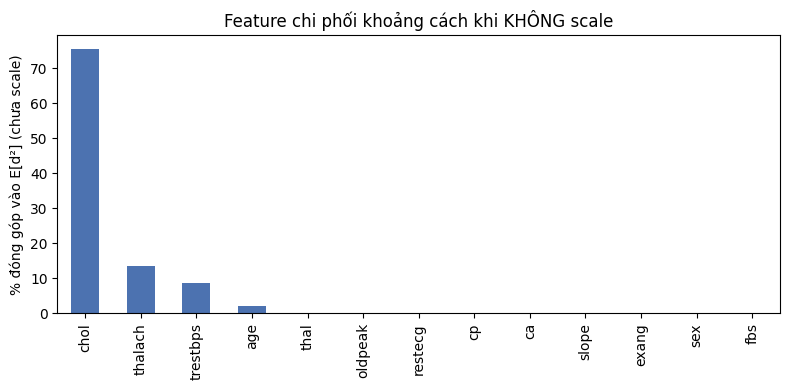

In [14]:
scale_tbl = X_train.describe().T[["min", "max", "std"]]
scale_tbl["range"] = scale_tbl["max"] - scale_tbl["min"]
scale_tbl = scale_tbl.sort_values("range", ascending=False)
display(scale_tbl.round(2))

# Đóng góp (%) của từng feature vào bình phương khoảng cách Euclid trung bình giữa 2 điểm ngẫu nhiên:
# E[(x_j - x'_j)^2] = 2*Var(x_j)  -> tỷ lệ = Var_j / sum(Var)
var_share = (X_train.var() / X_train.var().sum() * 100).sort_values(ascending=False)
plt.figure(figsize=(8, 4))
var_share.plot(kind="bar", color="#4C72B0")
plt.ylabel("% đóng góp vào E[d²] (chưa scale)")
plt.title("Feature chi phối khoảng cách khi KHÔNG scale")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/distance_dominance_unscaled.png", dpi=150); plt.show()

## 3. Grid search: `n_neighbors` × `metric` (có StandardScaler, chọn theo ROC-AUC)

In [15]:
pipe_scaled = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier()),
])
param_grid = {"knn__n_neighbors": K_RANGE, "knn__metric": METRICS}

gs_scaled = GridSearchCV(pipe_scaled, param_grid, scoring=SCORING, refit="roc_auc",
                         cv=cv, n_jobs=-1, return_train_score=True)
gs_scaled.fit(X_train, y_train)

print("Best params :", gs_scaled.best_params_)
print("Best ROC-AUC:", round(gs_scaled.best_score_, 4))

def to_df(gs, tag):
    r = pd.DataFrame(gs.cv_results_)
    df = pd.DataFrame({
        "k": r["param_knn__n_neighbors"].astype(int),
        "metric": r["param_knn__metric"],
        "acc_mean": r["mean_test_accuracy"], "acc_std": r["std_test_accuracy"],
        "auc_mean": r["mean_test_roc_auc"],  "auc_std": r["std_test_roc_auc"],
        "f1_mean": r["mean_test_f1"],
        "train_acc": r["mean_train_accuracy"],
    })
    df["setting"] = tag
    return df

res_scaled = to_df(gs_scaled, "Scaled")

Best params : {'knn__metric': 'manhattan', 'knn__n_neighbors': 17}
Best ROC-AUC: 0.8864


## 4. Đồ thị Accuracy theo k (sản phẩm bắt buộc) + ROC-AUC theo k

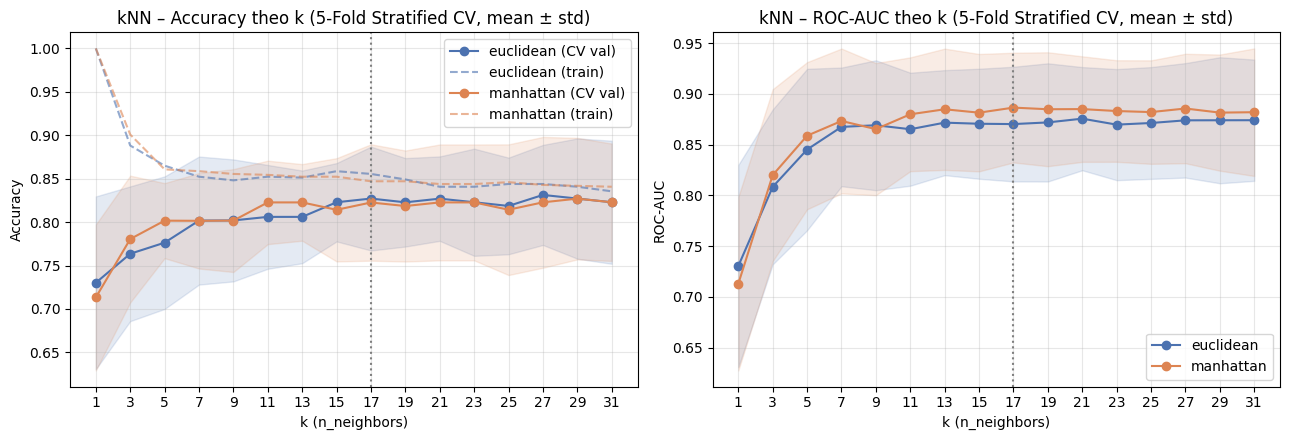

In [16]:
best_k = gs_scaled.best_params_["knn__n_neighbors"]
best_metric = gs_scaled.best_params_["knn__metric"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for m, c in zip(METRICS, ["#4C72B0", "#DD8452"]):
    d = res_scaled[res_scaled.metric == m].sort_values("k")
    axes[0].plot(d.k, d.acc_mean, "o-", color=c, label=f"{m} (CV val)")
    axes[0].fill_between(d.k, d.acc_mean - d.acc_std, d.acc_mean + d.acc_std, color=c, alpha=0.15)
    axes[0].plot(d.k, d.train_acc, "--", color=c, alpha=0.6, label=f"{m} (train)")
    axes[1].plot(d.k, d.auc_mean, "o-", color=c, label=m)
    axes[1].fill_between(d.k, d.auc_mean - d.auc_std, d.auc_mean + d.auc_std, color=c, alpha=0.15)
for ax, t in zip(axes, ["Accuracy", "ROC-AUC"]):
    ax.axvline(best_k, ls=":", color="gray")
    ax.set_xlabel("k (n_neighbors)"); ax.set_ylabel(t); ax.set_xticks(K_RANGE)
    ax.set_title(f"kNN – {t} theo k (5-Fold Stratified CV, mean ± std)"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/accuracy_auc_vs_k.png", dpi=150); plt.show()

**Đọc đồ thị (bias–variance):** k nhỏ (k=1) → train acc ≈ 1, val thấp ⇒ variance cao/overfit; k tăng → biên quyết định trơn hơn, val tăng rồi bão hòa; k quá lớn → underfit (tiến về dự đoán lớp đa số). Ghi nhận khoảng k "ổn định" chứ không chỉ 1 điểm cực đại.

## 5. Euclidean vs Manhattan

In [17]:
cmp_metric = (res_scaled.loc[res_scaled.groupby("metric")["auc_mean"].idxmax()]
              [["metric", "k", "acc_mean", "acc_std", "auc_mean", "auc_std", "f1_mean"]]
              .reset_index(drop=True))
display(cmp_metric.round(4))

# So sánh cặp đôi trên cùng k: chênh lệch ROC-AUC trung bình theo k
piv = res_scaled.pivot(index="k", columns="metric", values="auc_mean")
piv["diff (manhattan - euclidean)"] = piv["manhattan"] - piv["euclidean"]
display(piv.round(4))

,metric,k,acc_mean,acc_std,auc_mean,auc_std,f1_mean
0,euclidean,21,0.8270,0.0486,0.8755,0.0508,0.7889
1,manhattan,17,0.8226,0.0670,0.8864,0.0540,0.7896


metric,euclidean,manhattan,diff (manhattan - euclidean)
k,,,
1,0.7304,0.7129,-0.0175
3,0.8083,0.8199,0.0116
5,0.8451,0.8587,0.0136
7,0.8674,0.8732,0.0058
9,0.8690,0.8652,-0.0038
11,0.8651,0.8798,0.0147
13,0.8716,0.8848,0.0132
15,0.8705,0.8814,0.0109
17,0.8702,0.8864,0.0162


**Diễn giải gợi ý:** Manhattan ($L_1$) cộng tuyến tính độ lệch → ít nhạy với outlier/độ lệch lớn ở một chiều hơn Euclidean ($L_2$, bình phương). Dữ liệu có nhiều feature rời rạc/thứ bậc (cp, slope, ca, thal, restecg) ⇒ $L_1$ thường hợp lý hơn. Nếu chênh lệch < std giữa các fold thì kết luận: **không khác biệt có ý nghĩa** — ghi rõ điều này trong báo cáo.

## 6. Chứng minh tác dụng của StandardScaler (ablation: cùng grid, bỏ scaler)

No scaling  – best: {'knn__metric': 'manhattan', 'knn__n_neighbors': 7} | ROC-AUC = 0.7591
With scaler – best: {'knn__metric': 'manhattan', 'knn__n_neighbors': 17} | ROC-AUC = 0.8864


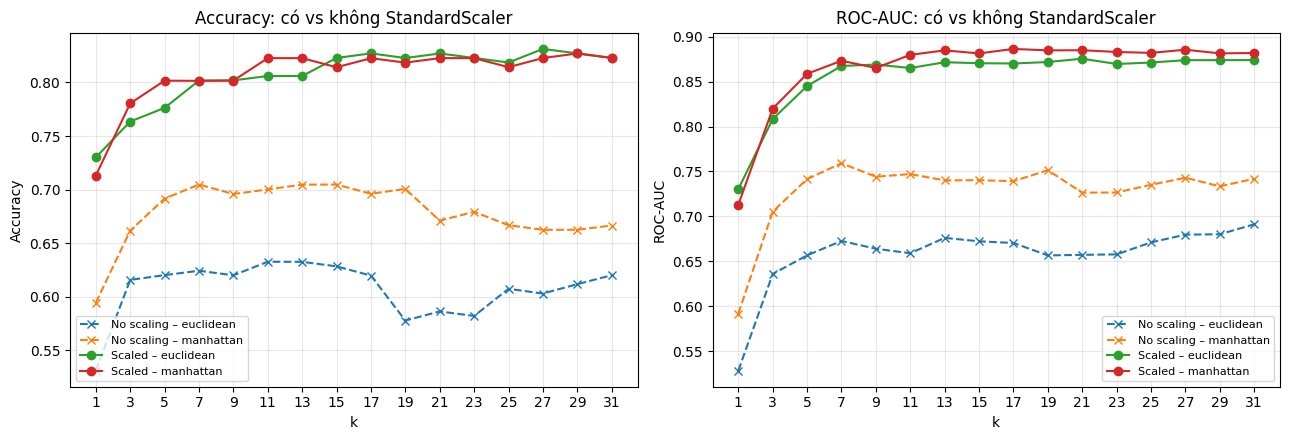

,Setting,Best_params,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,roc_auc_std
0,No scaling,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.7048,0.7103,0.6130,0.6517,0.7591,0.058
1,StandardScaler,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.8226,0.8432,0.7511,0.7896,0.8864,0.054


Cùng k=17, manhattan: Acc 0.6962 -> 0.8226 | AUC 0.7392 -> 0.8864


In [18]:
pipe_raw = Pipeline([("knn", KNeighborsClassifier())])
gs_raw = GridSearchCV(pipe_raw, param_grid, scoring=SCORING, refit="roc_auc",
                      cv=cv, n_jobs=-1, return_train_score=True)
gs_raw.fit(X_train, y_train)
res_raw = to_df(gs_raw, "No scaling")

print("No scaling  – best:", gs_raw.best_params_, "| ROC-AUC =", round(gs_raw.best_score_, 4))
print("With scaler – best:", gs_scaled.best_params_, "| ROC-AUC =", round(gs_scaled.best_score_, 4))

both = pd.concat([res_scaled, res_raw])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col, t in zip(axes, ["acc_mean", "auc_mean"], ["Accuracy", "ROC-AUC"]):
    for (setting, m), d in both.groupby(["setting", "metric"]):
        d = d.sort_values("k")
        ax.plot(d.k, d[col], "o-" if setting == "Scaled" else "x--", label=f"{setting} – {m}")
    ax.set_xlabel("k"); ax.set_ylabel(t); ax.set_xticks(K_RANGE); ax.grid(alpha=0.3)
    ax.set_title(f"{t}: có vs không StandardScaler"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/scaler_effect.png", dpi=150); plt.show()

# Bảng tổng hợp tại best config của mỗi setting
def best_row(gs, tag):
    i = gs.best_index_; r = gs.cv_results_
    return {"Setting": tag, "Best_params": gs.best_params_,
            **{f"{s}_mean": r[f"mean_test_{s}"][i] for s in SCORING},
            "roc_auc_std": r["std_test_roc_auc"][i]}
display(pd.DataFrame([best_row(gs_raw, "No scaling"), best_row(gs_scaled, "StandardScaler")]).round(4))

# Cùng 1 cấu hình (best của bản scaled) -> chênh lệch thuần do scaling
same = res_raw[(res_raw.k == best_k) & (res_raw.metric == best_metric)].iloc[0]
best_s = res_scaled[(res_scaled.k == best_k) & (res_scaled.metric == best_metric)].iloc[0]
print(f"Cùng k={best_k}, {best_metric}: Acc {same.acc_mean:.4f} -> {best_s.acc_mean:.4f} | "
      f"AUC {same.auc_mean:.4f} -> {best_s.auc_mean:.4f}")

**Lập luận:** $d(x,x')=\sqrt{\sum_j (x_j-x'_j)^2}$ ⇒ đóng góp của feature $j$ tỉ lệ với $\mathrm{Var}(x_j)$. Không scale thì chol/thalach/trestbps chiếm phần lớn $E[d^2]$ (xem mục 2), trong khi các feature tương quan mạnh với target (thal, ca, oldpeak, exang, cp) có variance nhỏ bị "lấn át". StandardScaler đưa mọi feature về $\mathrm{Var}=1$ ⇒ mỗi feature đóng góp ngang nhau ⇒ hàng xóm gần nhất phản ánh tương đồng lâm sàng thật hơn.

## 7. Dictionary kết quả (CV trên Train, theo format chung)

In [19]:
i = gs_scaled.best_index_; r = gs_scaled.cv_results_
results_kNN = {
    "Model": "kNN",
    "Accuracy_mean": float(r["mean_test_accuracy"][i]),
    "Accuracy_std":  float(r["std_test_accuracy"][i]),
    "Precision_mean": float(r["mean_test_precision"][i]),
    "Recall_mean":   float(r["mean_test_recall"][i]),
    "F1_mean":       float(r["mean_test_f1"][i]),
    "ROC_AUC_mean":  float(r["mean_test_roc_auc"][i]),
    "Best_params": {"n_neighbors": int(best_k), "metric": best_metric, "weights": "uniform"},
    "Note": (f"Pipeline(StandardScaler -> KNN); grid k∈{{1,3,...,31}} × {{euclidean, manhattan}}, "
             f"chọn theo ROC-AUC trên 5-Fold StratifiedKFold(rs=42). "
             f"Không scaler: best ROC-AUC={gs_raw.best_score_:.4f} vs có scaler={gs_scaled.best_score_:.4f}."),
}
print(json.dumps(results_kNN, indent=2, ensure_ascii=False))

{
  "Model": "kNN",
  "Accuracy_mean": 0.8226063829787235,
  "Accuracy_std": 0.06701705491600782,
  "Precision_mean": 0.843180410920349,
  "Recall_mean": 0.751082251082251,
  "F1_mean": 0.7896065640498302,
  "ROC_AUC_mean": 0.8864119214119214,
  "Best_params": {
    "n_neighbors": 17,
    "metric": "manhattan",
    "weights": "uniform"
  },
  "Note": "Pipeline(StandardScaler -> KNN); grid k∈{1,3,...,31} × {euclidean, manhattan}, chọn theo ROC-AUC trên 5-Fold StratifiedKFold(rs=42). Không scaler: best ROC-AUC=0.7591 vs có scaler=0.8864."
}


## 8. Đánh giá trên Test (báo cáo RIÊNG, không dùng để chọn tham số)

,value
Model,kNN
Test_Accuracy,0.866667
Test_Precision,0.916667
Test_Recall,0.785714
Test_F1,0.846154
Test_ROC_AUC,0.959263


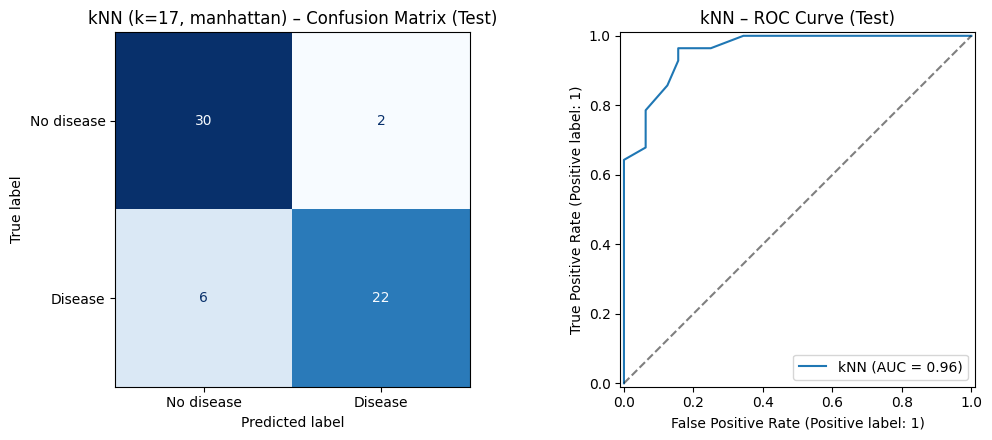

In [20]:
best_model = gs_scaled.best_estimator_          # đã refit trên toàn bộ X_train
y_pred  = best_model.predict(X_test)
y_score = best_model.predict_proba(X_test)[:, 1]   # xác suất lớp bệnh (target=1)

test_kNN = {
    "Model": "kNN",
    "Test_Accuracy":  accuracy_score(y_test, y_pred),
    "Test_Precision": precision_score(y_test, y_pred, zero_division=0),
    "Test_Recall":    recall_score(y_test, y_pred),
    "Test_F1":        f1_score(y_test, y_pred),
    "Test_ROC_AUC":   roc_auc_score(y_test, y_score),
}
display(pd.Series(test_kNN).to_frame("value"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["No disease", "Disease"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"kNN (k={best_k}, {best_metric}) – Confusion Matrix (Test)")
RocCurveDisplay.from_predictions(y_test, y_score, name="kNN", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5); axes[1].set_title("kNN – ROC Curve (Test)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/test_cm_roc.png", dpi=150); plt.show()

Lưu ý: với kNN (`weights='uniform'`), `predict_proba` = tỷ lệ hàng xóm thuộc lớp 1 ⇒ chỉ có $k+1$ mức rời rạc ⇒ ROC curve dạng bậc thang, AUC có thể thấp hơn mô hình cho score liên tục (LR, SVM). Nên nêu điểm này trong phần phân tích.

## 9. Xuất file cho TV5

In [22]:
with open(f"{OUT_DIR}/results_kNN.json", "w", encoding="utf-8") as f:
    json.dump(results_kNN, f, indent=2, ensure_ascii=False)
with open(f"{OUT_DIR}/test_kNN.json", "w", encoding="utf-8") as f:
    json.dump({k: (float(v) if not isinstance(v, str) else v) for k, v in test_kNN.items()}, f, indent=2)
np.save(f"{OUT_DIR}/y_pred_kNN.npy", y_pred)
np.save(f"{OUT_DIR}/y_score_kNN.npy", y_score)
joblib.dump(best_model, f"{OUT_DIR}/kNN_best_model.joblib")
both.to_csv(f"{OUT_DIR}/cv_grid_results_kNN.csv", index=False)
print(sorted(os.listdir(OUT_DIR)))

['accuracy_auc_vs_k.png', 'cv_grid_results_kNN.csv', 'distance_dominance_unscaled.png', 'kNN_best_model.joblib', 'results_kNN.json', 'scaler_effect.png', 'test_cm_roc.png', 'test_kNN.json', 'y_pred_kNN.npy', 'y_score_kNN.npy']


In [23]:
!zip -rq results_kNN.zip results_kNN
from google.colab import files
files.download("results_kNN.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>